# Comparación baseline full vs máscara (RoCoLe)

Comparar los baselines con foto completa y con máscara COCO sobre las mismas 226 hojas de prueba, leyendo solo lo ya guardado, para dejar claro qué mide la columna test y si la máscara realmente mejora. Este cuaderno no reentrena ni toca los 01–04.


## Semilla fija

**Entrada:** ninguna.

**Qué hacemos:** fijamos la semilla del proyecto para que cualquier azar futuro se pueda repetir. Aquí no entrenamos; la dejamos por coherencia con el resto de cuadernos RoCoLe.

**Salida:** seed.


In [1]:
# Entrada
# ninguna

# Qué hacemos
seed = 42

# Salida
seed


42

## Rutas de tablas y resultados

**Entrada:** ninguna.

**Qué hacemos:** localizamos la tabla full, la tabla con máscara, el índice de hojas y la carpeta de resultados, todas relativas al repo.

**Salida:** full_features_path, masked_features_path, index_path, results_dir.


In [2]:
# Entrada
from pathlib import Path

# Qué hacemos
full_features_path = Path("../../data/featured/rocole/rgb_glcm_features.csv")
masked_features_path = Path("../../data/featured/rocole/rgb_glcm_features_masked.csv")
index_path = Path("../../data/featured/rocole/index.csv")
results_dir = Path("../../experiments/results")

# Salida
print("full_features_path:", full_features_path.resolve(), "existe:", full_features_path.exists())
print("masked_features_path:", masked_features_path.resolve(), "existe:", masked_features_path.exists())
print("index_path:", index_path.resolve(), "existe:", index_path.exists())
print("results_dir:", results_dir.resolve(), "existe:", results_dir.exists())
full_features_path, masked_features_path, index_path, results_dir


full_features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features.csv existe: True
masked_features_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\rgb_glcm_features_masked.csv existe: True
index_path: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\data\featured\rocole\index.csv existe: True
results_dir: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results existe: True


(WindowsPath('../../data/featured/rocole/rgb_glcm_features.csv'),
 WindowsPath('../../data/featured/rocole/rgb_glcm_features_masked.csv'),
 WindowsPath('../../data/featured/rocole/index.csv'),
 WindowsPath('../../experiments/results'))

## Cargar características full

**Entrada:** full_features_path.

**Qué hacemos:** leemos la tabla de medidas sobre hoja completa. Conservamos File, split, link_group y Binary.Label; no inventamos un reparto.

**Salida:** full_features.


In [3]:
# Entrada
import pandas as pd

# Qué hacemos
full_features = pd.read_csv(full_features_path)

# Salida
print("filas:", len(full_features))
print("columnas:", list(full_features.columns))
full_features.head()


filas: 1481
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.261530,0.206835,0.141426,0.118705,0.210467,1.706653e-01,0.603388,0.798073,0.161943
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.167154,0.198152,0.082722,0.129672,-423.730733,1.340577e+06,0.739996,0.774939,0.139027
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.229394,0.264305,0.118196,0.141937,0.164238,2.007234e-01,0.638387,0.784853,0.147145
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.167927,0.147516,0.081697,0.085211,41580.329422,6.349106e+06,0.590025,0.785764,0.152910
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.253770,0.231036,0.118870,0.146720,127.325844,3.505966e+05,0.614583,0.805190,0.149165


## Cargar características con máscara

**Entrada:** masked_features_path.

**Qué hacemos:** leemos la tabla de las mismas medidas, pero solo dentro de la máscara de hoja. Misma estructura que full.

**Salida:** masked_features.


In [4]:
# Entrada
# masked_features_path

# Qué hacemos
masked_features = pd.read_csv(masked_features_path)

# Salida
print("filas:", len(masked_features))
print("columnas:", list(masked_features.columns))
masked_features.head()


filas: 1481
columnas: ['File', 'split', 'link_group', 'Binary.Label', 'Multiclass.Label', 'error', 'exg_mean', 'exg_std', 'ngrdi_mean', 'ngrdi_std', 'vari_mean', 'vari_std', 'glcm_contrast', 'glcm_homogeneity', 'glcm_energy']


,File,split,link_group,Binary.Label,Multiclass.Label,error,exg_mean,exg_std,ngrdi_mean,ngrdi_std,vari_mean,vari_std,glcm_contrast,glcm_homogeneity,glcm_energy
0,C1P1H1.jpg,train,74,healthy,healthy,NaN,0.466084,0.197243,0.250576,0.079053,0.348592,0.076514,0.684317,0.895943,0.381573
1,C1P2E2.jpg,train,84,unhealthy,rust_level_2,NaN,0.324993,0.094060,0.130550,0.068199,0.180603,0.094060,0.636574,0.897060,0.414018
2,C1P2H1.jpg,train,84,healthy,healthy,NaN,0.427245,0.191211,0.199764,0.056161,0.272501,0.049086,0.650484,0.886744,0.405814
3,C1P3E1.jpg,train,95,healthy,healthy,NaN,0.222965,0.062609,0.106283,0.021579,0.165645,0.029721,0.549393,0.927267,0.513788
4,C1P3E2.jpg,train,95,unhealthy,rust_level_2,NaN,0.237410,0.106820,0.062168,0.077000,0.085289,0.112395,0.660769,0.895654,0.415801


## Cargar índice de hojas

**Entrada:** index_path.

**Qué hacemos:** leemos el índice featured con File, split, link_group y Binary.Label. Es la referencia del reparto train/val/test.

**Salida:** leaf_index.


In [5]:
# Entrada
# index_path

# Qué hacemos
leaf_index = pd.read_csv(index_path)

# Salida
print("filas:", len(leaf_index))
print("columnas:", list(leaf_index.columns))
leaf_index.head()


filas: 1481
columnas: ['File', 'plant_key', 'link_group', 'Binary.Label', 'Multiclass.Label', 'leaf_face', 'split', 'photo_path']


,File,plant_key,link_group,Binary.Label,Multiclass.Label,leaf_face,split,photo_path
0,C1P1H1.jpg,C1P1,74,healthy,healthy,H,train,data/curated/rocole/photos/C1P1H1.jpg
1,C1P2E2.jpg,C1P2,84,unhealthy,rust_level_2,E,train,data/curated/rocole/photos/C1P2E2.jpg
2,C1P2H1.jpg,C1P2,84,healthy,healthy,H,train,data/curated/rocole/photos/C1P2H1.jpg
3,C1P3E1.jpg,C1P3,95,healthy,healthy,E,train,data/curated/rocole/photos/C1P3E1.jpg
4,C1P3E2.jpg,C1P3,95,unhealthy,rust_level_2,E,train,data/curated/rocole/photos/C1P3E2.jpg


## ¿Full y máscara van en el mismo orden?

**Entrada:** full_features, masked_features, leaf_index.

**Qué hacemos:** comprobamos que File, split, link_group y Binary.Label coinciden fila a fila entre full, máscara e índice, y que hay 1481 filas. Si falla, la comparación de baselines no es válida.

**Salida:** alignment_ok.


In [6]:
# Entrada
# full_features, masked_features, leaf_index
meta_cols = ["File", "split", "link_group", "Binary.Label"]

# Qué hacemos
full_meta = full_features[meta_cols].reset_index(drop=True)
masked_meta = masked_features[meta_cols].reset_index(drop=True)
index_meta = leaf_index[meta_cols].reset_index(drop=True)

alignment_ok = (
    len(full_features) == 1481
    and len(masked_features) == 1481
    and len(leaf_index) == 1481
    and full_meta.equals(masked_meta)
    and full_meta.equals(index_meta)
)

# Salida
print("n full:", len(full_features), "n masked:", len(masked_features), "n index:", len(leaf_index))
print("alignment_ok:", alignment_ok)
alignment_ok


n full: 1481 n masked: 1481 n index: 1481
alignment_ok: True


True

## ¿Algún link_group mezcla splits?

**Entrada:** leaf_index.

**Qué hacemos:** agrupamos por link_group y contamos cuántos valores distintos de split aparecen. Ningún grupo debería tener más de uno: la misma planta no puede estar en aprender y en prueba.

**Salida:** link_group_split_ok.


In [7]:
# Entrada
# leaf_index

# Qué hacemos
splits_per_link_group = leaf_index.groupby("link_group")["split"].nunique()
link_group_split_ok = bool((splits_per_link_group <= 1).all())

# Salida
print("link_groups con más de un split:", int((splits_per_link_group > 1).sum()))
print("link_group_split_ok:", link_group_split_ok)
link_group_split_ok


link_groups con más de un split: 0
link_group_split_ok: True


True

## Conteos por split en full y máscara

**Entrada:** full_features, masked_features.

**Qué hacemos:** contamos cuántas hojas caen en train, val y test en cada tabla. Deben coincidir: el reparto es el mismo.

**Salida:** split_counts.


In [8]:
# Entrada
# full_features, masked_features

# Qué hacemos
split_counts = pd.DataFrame(
    {
        "full": full_features["split"].value_counts(),
        "masked": masked_features["split"].value_counts(),
    }
).sort_index()

# Salida
print(split_counts)
split_counts


       full  masked
split              
test    226     226
train  1037    1037
val     218     218


,full,masked
split,,
test,226,226
train,1037,1037
val,218,218


## Etiquetas en el holdout de test

**Entrada:** full_features, masked_features.

**Qué hacemos:** en las hojas con split igual a test, contamos healthy frente a unhealthy en ambas tablas. Esperamos 115 sanas y 111 afectadas (226 en total).

**Salida:** test_label_counts.


In [9]:
# Entrada
# full_features, masked_features

# Qué hacemos
full_test_labels = full_features.loc[full_features["split"] == "test", "Binary.Label"]
masked_test_labels = masked_features.loc[masked_features["split"] == "test", "Binary.Label"]
test_label_counts = pd.DataFrame(
    {
        "full": full_test_labels.value_counts(),
        "masked": masked_test_labels.value_counts(),
    }
).sort_index()

# Salida
print("n test full:", len(full_test_labels), "n test masked:", len(masked_test_labels))
print("esperado: healthy 115, unhealthy 111")
print(test_label_counts)
test_label_counts


n test full: 226 n test masked: 226
esperado: healthy 115, unhealthy 111
              full  masked
Binary.Label              
healthy        115     115
unhealthy      111     111


,full,masked
Binary.Label,,
healthy,115,115
unhealthy,111,111


## Qué significa train, val y test aquí

El índice featured ya apartó las hojas en tres grupos, por planta (link_group), para que la misma planta no aparezca en dos lados.

- **train** (1037 hojas): ahí se ajustaron los modelos en los cuadernos 04. Solo se usa para aprender pesos o árboles.
- **val** (218 hojas): ahí se eligieron hiperparámetros (C de la logística, n_estimators y max_depth del bosque). No es el número que reportamos como acierto final.
- **test** (226 hojas): holdout. Se mira **una sola vez** al final de cada 04, con el f1_macro de test. No se usa para elegir columnas, umbrales ni hiperparámetros.

Este cuaderno 05 no vuelve a entrenar ni a tocar test para decidir nada: solo lee las métricas y matrices que ya salieron de esos holdouts.


## Métricas de test del baseline full

**Entrada:** results_dir.

**Qué hacemos:** cargamos el CSV de métricas de test del baseline sin máscara (ya guardado por el 04 full). No recalculamos f1.

**Salida:** full_metrics.


In [10]:
# Entrada
# results_dir

# Qué hacemos
full_metrics_path = results_dir / "rocole_baseline_metrics.csv"
full_metrics = pd.read_csv(full_metrics_path)

# Salida
print("ruta:", full_metrics_path.resolve(), "existe:", full_metrics_path.exists())
full_metrics


ruta: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_metrics.csv existe: True


,modelo,f1_macro_test,best_C,n_estimators,max_depth
0,logistica,0.561732,0.1,NaN,NaN
1,random_forest,0.548354,NaN,100.0,5.0


## Métricas de test del baseline con máscara

**Entrada:** results_dir.

**Qué hacemos:** cargamos el CSV de métricas de test del baseline con máscara (ya guardado por el 04 masked). Tampoco recalculamos.

**Salida:** masked_metrics.


In [11]:
# Entrada
# results_dir

# Qué hacemos
masked_metrics_path = results_dir / "rocole_baseline_masked_metrics.csv"
masked_metrics = pd.read_csv(masked_metrics_path)

# Salida
print("ruta:", masked_metrics_path.resolve(), "existe:", masked_metrics_path.exists())
masked_metrics


ruta: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_metrics.csv existe: True


,modelo,f1_macro_test,best_C,n_estimators,max_depth
0,logistica,0.606187,0.1,NaN,NaN
1,random_forest,0.676934,NaN,200.0,10.0


## Comparación en val del baseline full

**Entrada:** results_dir.

**Qué hacemos:** leemos la tabla de f1_macro en val (mayoría, logística, bosque) del corrido full. Sirve para recordar qué ganó en validación, no como acierto final.

**Salida:** full_val_comparison.


In [12]:
# Entrada
# results_dir

# Qué hacemos
full_val_path = results_dir / "rocole_baseline_val_comparison.csv"
full_val_comparison = pd.read_csv(full_val_path)

# Salida
print("ruta:", full_val_path.resolve(), "existe:", full_val_path.exists())
full_val_comparison


ruta:

 D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_val_comparison.csv existe: True


,modelo,f1_macro_val
0,mayoria,0.341390
1,logistica,0.617455
2,random_forest,0.629252


## Comparación en val del baseline con máscara

**Entrada:** results_dir.

**Qué hacemos:** leemos la tabla de f1_macro en val del corrido con máscara. Misma lectura: val eligió; test ya se midió aparte.

**Salida:** masked_val_comparison.


In [13]:
# Entrada
# results_dir

# Qué hacemos
masked_val_path = results_dir / "rocole_baseline_masked_val_comparison.csv"
masked_val_comparison = pd.read_csv(masked_val_path)

# Salida
print("ruta:", masked_val_path.resolve(), "existe:", masked_val_path.exists())
masked_val_comparison


ruta: D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_val_comparison.csv existe: True


,modelo,f1_macro_val
0,mayoria,0.341390
1,logistica,0.715501
2,random_forest,0.743119


## Tabla lado a lado: test full vs máscara

**Entrada:** full_metrics, masked_metrics, full_val_comparison, masked_val_comparison.

**Qué hacemos:** unimos por modelo el f1_macro de test de full y de máscara (y el f1_macro de val como contexto). Esperado aproximado en test: full log 0.56 / RF 0.55; masked log 0.61 / RF 0.68. Sin reentrenar.

**Salida:** metrics_comparison.


In [14]:
# Entrada
# full_metrics, masked_metrics, full_val_comparison, masked_val_comparison

# Qué hacemos
full_side = full_metrics.add_suffix("_full").rename(columns={"modelo_full": "modelo"})
masked_side = masked_metrics.add_suffix("_masked").rename(columns={"modelo_masked": "modelo"})
metrics_comparison = full_side.merge(masked_side, on="modelo", how="outer")

full_val = full_val_comparison.rename(columns={"f1_macro_val": "f1_macro_val_full"})
masked_val = masked_val_comparison.rename(columns={"f1_macro_val": "f1_macro_val_masked"})
metrics_comparison = metrics_comparison.merge(full_val, on="modelo", how="left")
metrics_comparison = metrics_comparison.merge(masked_val, on="modelo", how="left")

# Salida
print(metrics_comparison.to_string(index=False))
metrics_comparison


       modelo  f1_macro_test_full  best_C_full  n_estimators_full  max_depth_full  f1_macro_test_masked  best_C_masked  n_estimators_masked  max_depth_masked  f1_macro_val_full  f1_macro_val_masked
    logistica            0.561732          0.1                NaN             NaN              0.606187            0.1                  NaN               NaN           0.617455             0.715501
random_forest            0.548354          NaN              100.0             5.0              0.676934            NaN                200.0              10.0           0.629252             0.743119


,modelo,f1_macro_test_full,best_C_full,n_estimators_full,max_depth_full,f1_macro_test_masked,best_C_masked,n_estimators_masked,max_depth_masked,f1_macro_val_full,f1_macro_val_masked
0,logistica,0.561732,0.1,NaN,NaN,0.606187,0.1,NaN,NaN,0.617455,0.715501
1,random_forest,0.548354,NaN,100.0,5.0,0.676934,NaN,200.0,10.0,0.629252,0.743119


## Matrices de confusión de test (números del 04)

**Entrada:** ninguna tabla nueva de predicciones.

**Qué hacemos:** documentamos las matrices ya obtenidas en los cuadernos 04 (full y masked), sin recalcularlas. Filas = verdad (healthy, unhealthy); columnas = predicción (healthy, unhealthy).

Números verificados:
- full logística: [[61, 54], [45, 66]]
- full bosque: [[59, 56], [46, 65]]
- masked logística: [[69, 46], [43, 68]]
- masked bosque: [[78, 37], [36, 75]]

**Salida:** confusion_tables.


In [15]:
# Entrada
import numpy as np

# Qué hacemos
# Números tomados de los 04 ya corridos; no se recalculan aquí.
confusion_tables = {
    "full_logistic": np.array([[61, 54], [45, 66]]),
    "full_rf": np.array([[59, 56], [46, 65]]),
    "masked_logistic": np.array([[69, 46], [43, 68]]),
    "masked_rf": np.array([[78, 37], [36, 75]]),
}

# Salida
for name, matrix in confusion_tables.items():
    print(name)
    print(matrix)
    print("filas=verdad healthy/unhealthy; cols=pred healthy/unhealthy")
    print()
confusion_tables


full_logistic
[[61 54]
 [45 66]]
filas=verdad healthy/unhealthy; cols=pred healthy/unhealthy

full_rf
[[59 56]
 [46 65]]
filas=verdad healthy/unhealthy; cols=pred healthy/unhealthy

masked_logistic
[[69 46]
 [43 68]]
filas=verdad healthy/unhealthy; cols=pred healthy/unhealthy

masked_rf
[[78 37]
 [36 75]]
filas=verdad healthy/unhealthy; cols=pred healthy/unhealthy



{'full_logistic': array([[61, 54],
        [45, 66]]),
 'full_rf': array([[59, 56],
        [46, 65]]),
 'masked_logistic': array([[69, 46],
        [43, 68]]),
 'masked_rf': array([[78, 37],
        [36, 75]])}

## Figuras de confusión ya guardadas

**Entrada:** results_dir.

**Qué hacemos:** listamos las cuatro PNG de matrices de confusión de test ya guardadas en results. Si el archivo existe, lo mostramos con Image; si no, solo avisamos la ruta. No regeneramos las figuras.

**Salida:** confusion_figure_paths.


full_logistic -> D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_logistic_confusion.png existe: True


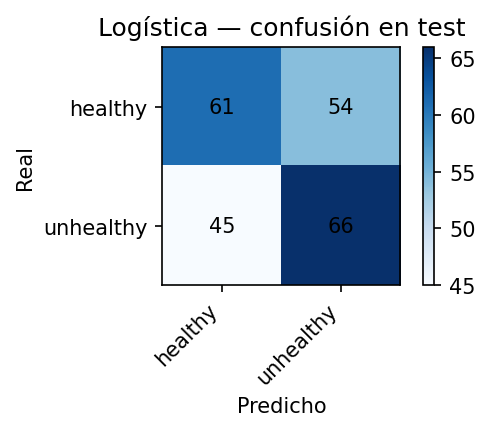

full_rf -> D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_rf_confusion.png existe: True


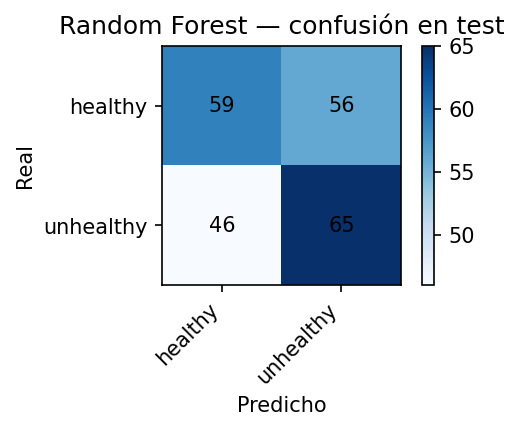

masked_logistic -> D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_logistic_confusion.png existe: True


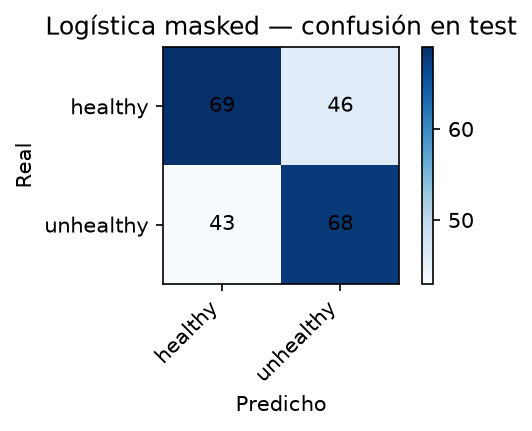

masked_rf -> D:\Maestria\Documentos\Proyecto de innovación tecnologica en IA\Desarrollo\diagnostico-hojas-cafe\experiments\results\rocole_baseline_masked_rf_confusion.png existe: True


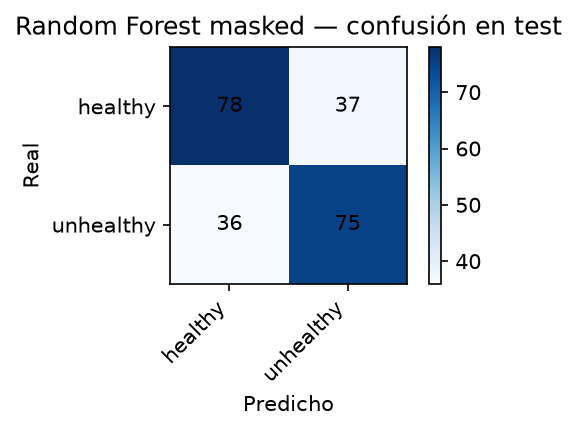

{'full_logistic': WindowsPath('../../experiments/results/rocole_baseline_logistic_confusion.png'),
 'full_rf': WindowsPath('../../experiments/results/rocole_baseline_rf_confusion.png'),
 'masked_logistic': WindowsPath('../../experiments/results/rocole_baseline_masked_logistic_confusion.png'),
 'masked_rf': WindowsPath('../../experiments/results/rocole_baseline_masked_rf_confusion.png')}

In [16]:
# Entrada
from IPython.display import Image, display

# Qué hacemos
confusion_figure_paths = {
    "full_logistic": results_dir / "rocole_baseline_logistic_confusion.png",
    "full_rf": results_dir / "rocole_baseline_rf_confusion.png",
    "masked_logistic": results_dir / "rocole_baseline_masked_logistic_confusion.png",
    "masked_rf": results_dir / "rocole_baseline_masked_rf_confusion.png",
}

# Salida
for name, path in confusion_figure_paths.items():
    print(name, "->", path.resolve(), "existe:", path.exists())
    if path.exists():
        display(Image(filename=str(path)))
confusion_figure_paths


## Conclusiones

Misma base de hojas (226 en test): full y masked miden distinto sobre las mismas fotos. La máscara mejora el f1_macro de test, sobre todo en el random forest. El número de test es holdout, no acierto de entrenamiento. Este cuaderno no reentrenó ni rehizo splits: solo leyó lo ya guardado.
